In [43]:
import os
from pathlib import Path
import pandas as pd
import librosa

import numpy as np
import matplotlib.pyplot as plt
from numpy import ndarray
import random
import glob
import matplotlib.pyplot as plt
from tqdm import tqdm
import pyworld as pw
import pysptk

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from IPython.display import display, Audio

from lazypredict.Supervised import LazyClassifier
from sklearn.model_selection import train_test_split 

import scipy
import scipy.signal
import numpy as np
import copy 

from pysptk.synthesis import AllPoleDF
from pysptk.synthesis import Synthesizer

In [39]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Define the model part using lazypredict


In [40]:
def classifing_lazypredict(data_train, data_test, feat_names, label_name):

    clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
    X_train = data_train[feat_names].to_numpy()
    X_test = data_test[feat_names].to_numpy()
    y_train = data_train[label_name].to_numpy()
    y_test = data_test[label_name].to_numpy()
    _, metrics = clf.fit(X_train, X_test, y_train, y_test);
    
    model_dictionary = clf.provide_models(X_train, X_test, y_train, y_test)
    return model_dictionary, metrics

# Common functions

## Data I/O

In [6]:
def load_audio(audio_path):
    return librosa.load(audio_path, sr=None)
    

class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()

## Analyze and reconstruct waveforms

In [44]:
def pyworld_analysis(input_wav, sr, fs=5):
    # analysis
    x = np.array(input_wav, dtype=np.float64)
    _f0, t = pw.dio(x, sr, frame_period=fs)    # raw pitch extractor
    f0 = pw.stonemask(x, _f0, t, sr)  # pitch refinement
    sp = pw.cheaptrick(x, f0, t, sr)  # extract smoothed spectrogram
    ap = pw.d4c(x, f0, t, sr)         # extract aperiodicity
    return f0, sp, ap, sr

def pyworld_synthesis(f0, sp, ap, sr, fs=5):
    # synthesis the original waveform
    y = pw.synthesize(f0, sp, ap, sr, frame_period=fs) # synthesize an utterance using the parameters
    return y

def reconstruct_wav_f0(orig_wav, f0_traj_mod, sr, period):
    # set unvoiced region to 0.0
    f0_traj_mod_ = np.zeros_like(f0_traj_mod) + f0_traj_mod
    f0_traj_mod_[f0_traj_mod_ != f0_traj_mod_] = 0.0

    # analysis
    _, sp, ap, sr = pyworld_analysis(orig_wav, sr, period)
    # re-construct
    return np.array(pyworld_synthesis(f0_traj_mod_, sp, ap, sr, period), dtype=orig_wav.dtype)

def synthesize_from_lsf(lsf, f0, hop_length=160, sampling_rate=16000):
    # 1. Convert LSF back to LPC
    # lpc_coeffs shape: (NumFrames, order + 1)
    lpc = pysptk.sptk.lsp2lpc(lsf)
    
    # 2. Generate Excitation Signal (Source)
    # This creates a pulse train for voiced and noise for unvoiced speech
    excitation = pysptk.excite(f0, hop_length)
    
    # Synthesis filter: 1 / A(z)
    
    # make sure lpc has loggain
    lpc[:, 0] = np.log(lpc[:, 0])
    
    synthesizer = Synthesizer(AllPoleDF(order=lpc.shape[1]-1), hop_length)
    
    x_synthesized = synthesizer.synthesis(excitation, lpc)
    return x_synthesized

## Feature Extraction

In [8]:
def feat_pipeline(file_list, mod_extraction, mod_manipulation, feat_name, debug=None):

    rows = []
    total = len(file_list)
        
    for cnt, i in tqdm(enumerate(file_list), total=len(file_list)):
        x, sr = load_audio(i)
        feat = mod_extraction(x)

        if mod_manipulation is not None:
            feat = mod_manipulation(feat)
           
        rows.append({
            "name": str(i.name),
            "{:s}".format(feat_name): feat,
        })
    
        if debug is not None and cnt >= debug:
            break
            
    dataframe = pd.DataFrame(rows)
    return dataframe

## Figure plotting

In [9]:
def plot_imshow(data, fig, axis, config_dic):
    plot_colorbar = False        
    if "plot_imshow" in config_dic:
        temp_dic = copy.deepcopy(config_dic["plot_imshow"])
        if "colorbar" in temp_dic:
            plot_colorbar = temp_dic['colorbar']
            temp_dic.pop("colorbar")
        pos = axis.imshow(data, **temp_dic)
    else:
        # default configuration
        pos = axis.imshow(data, cmap='jet', origin='lower', aspect='auto')
    if type(plot_colorbar) is dict:
        fig.colorbar(pos, **plot_colorbar)
    elif plot_colorbar:
        fig.colorbar(pos)
    else:
        pass
    return fig, axis
    
def _spec(data, fft_bins=4096, frame_shift=40, frame_length=240):
    f, t, cfft = scipy.signal.stft(
        data, nfft=fft_bins, 
        noverlap=frame_length-frame_shift, nperseg=frame_length)
    return f,t,cfft

def _amplitude(cfft):
    mag = np.power(np.power(np.real(cfft),2) + np.power(np.imag(cfft),2), 0.5)
    return mag

def _amplitude_to_db(mag):
    return 20*np.log10(mag+ np.finfo(np.float32).eps)

def _spec_amplitude(data, fft_bins=4096, frame_shift=40, frame_length=240):
    _, _, cfft = _spec(data, fft_bins, frame_shift, frame_length)
    mag  = _amplitude(cfft)
    return _amplitude_to_db(mag)

def plot_spec(data, fig, axis, config_dic):
    if type(data) is list:
        print("plot_spectrogram only supports data array input, ")
        print("but it receives list of data")
        sys.exit(1)
    
    # default configuration
    tmp_dic = copy.deepcopy(config_dic["plot_spec"]) \
              if "plot_spec" in config_dic else {}
    
    if "sampling_rate" in tmp_dic:
        sr = tmp_dic["sampling_rate"]  
        tmp_dic.pop("sampling_rate")
    else:
        sr = None
    if "frame_shift" in tmp_dic:
        fs = tmp_dic["frame_shift"]
        tmp_dic.pop("frame_shift")
    else:
        fs = 80
    if "frame_length" in tmp_dic:
        fl = tmp_dic["frame_length"]
        tmp_dic.pop("frame_length")
    else:
        fl =  320
    if "fft_bins" in tmp_dic:
        fn = tmp_dic["fft_bins"] 
        tmp_dic.pop("fft_bins")
    else:
        fn = 1024
    
    # stft
    spec = _spec_amplitude(data, fn, fs, fl)
    
    tmp_config_dic = config_dic.copy()
    if tmp_dic:
        tmp_config_dic["plot_imshow"] = tmp_dic

    plot_imshow(spec, fig, axis, tmp_config_dic)
    
    # options on label
    if "xlabel" not in config_dic:
        axis.set_xlabel("Frame index")
        
    if "ylabel" not in config_dic:
        if sr is None:
            axis.set_ylabel("Frequency bins")
        else:
            axis.set_ylabel("Frequency (Hz)")
            
    # ticks
    if "yticks" not in config_dic:            
        yticks_to_use = [(fn//2+1)//2, fn//2+1]
    else:
        yticks_to_use = config_dic["yticks"]
        config_dic.pop("yticks", None)
    
    axis.set_yticks(yticks_to_use)
    if sr is not None:
        freq_str = ["{:4.1f}".format(x * sr // 2 // 1000 / (fn//2+1)) \
                    for x in yticks_to_use]
        axis.set_yticklabels(freq_str)

    max_time = spec.shape[1] * fs / sr
    time_label = [np.floor(x) for x in np.linspace(0, max_time, 5)]
    xticks = [x * sr / fs for x in time_label]
    axis.set_xticks(xticks)
    axis.set_xticklabels(['{:.1f}'.format(x) for x in time_label])
    axis.set_xlabel('Time (s)')
    
    return fig, axis

# Fundamental frequency (F0)

## F0 Inconsistency
**Target system**: Concatenative TTS  
**Feature**: F0 trajectory  
**Manipulations**:  
  
- F0 segment shifting  
- F0 segment shuffling  

### Extraction

In [10]:
def extract_f0(waveform,
              fs, win_size, hop_size,
              fmin: int = 70, fmax: int = 400) -> ndarray:

    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = win_size // 2

    f0_freqs, _, _ = librosa.pyin(
        x, sr=fs,
        frame_length=win_size, hop_length=hop_size, center=True,
        win_length=autocorr_win_len, fmin=fmin, fmax=fmax, n_thresholds=7
    )


    # pyworld_analysis
    #x = np.array(x, dtype=np.float64)
    #_f0, t = pw.dio(x, sr)    # raw pitch extractor
    #f0_freqs = pw.stonemask(x, _f0, t, sr)  # pitch refinement
    
    return f0_freqs

### Manipulation

In [11]:
def f0_segment_shift(f0_traj, seg_len_s, hop_s, p_seg):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)
    i = 0

    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue

        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes, shift some
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)

            if np.random.rand() < p_seg:
                shift = random.choice([
                    random.uniform(0.87, 0.92),
                    random.uniform(1.08, 1.3)
                ])
                f0_mod[j:seg_j_end] *= shift

            j = seg_j_end

    return f0_mod


def f0_segment_shuffle(f0_traj, seg_len_s, hop_s, p_shuffle):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)

    segments = []
    indices = []

    i = 0
    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue
        
        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes    
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)
            
            segments.append(f0_mod[j:seg_j_end].copy())
            indices.append((j, seg_j_end))
            j = seg_j_end

    if len(segments) < 2:
        return f0_mod

    # partial shuffle
    perm = list(range(len(segments)))
    for i in range(len(perm)):
        if random.random() < p_shuffle:
            j = random.randrange(len(perm))
            perm[i], perm[j] = perm[j], perm[i]
            
    # re-insert
    for out_i, src_i in enumerate(perm):
        start, end = indices[out_i]
        seg = segments[src_i]
        L = min(end - start, len(seg))
        f0_mod[start:start + L] = seg[:L]
    
    return f0_mod        


def flatten_f0(f0_traj, strength=0.9, p=0.5):

    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    f0_ref = np.nanmedian(f0_mod)
    mask = (np.random.rand(len(f0_mod)) < p) & voiced

    f0_mod[mask] = (
        (1.0 - strength) * f0_mod[mask]
        + strength * f0_ref
    )

    return f0_mod


def apply_f0_mod(f0_traj, mod='shift', hop_s=0.016):
    
    if mod == 'shift':
        seg_len = random.uniform(0.08, 0.16)  # 80–160 ms
        p_seg = random.uniform(0.4, 0.7)

        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        
    elif mod == 'shuff':
        seg_len = random.uniform(0.08, 0.16)
        p_shuffle = random.uniform(0.2, 0.5)

        f0_traj_mod = f0_segment_shuffle(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )
        
    elif mod == 'flat':
        f0_traj_mod = flatten_f0(
            f0_traj,
            strength=0.5,
            p=1
        )
        
    else:
        f0_traj_mod = None
        print("Manipulation not recognized.")
        
    return f0_traj_mod

### Demonstration (optional)

In [12]:
p = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
f = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac'

df_all = pd.read_csv(p, sep=' ', header=None)

df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f) / f"{x}.flac"
    ))[['path']]
)

# selected_files = random.sample(df_real['path'].tolist(), 5)
selected_files = df_real['path'].tolist()

In [13]:
mod = 'shift'
fs = 16000
stft_params = STFTWindowParams()

# using a single utterance
filepath = selected_files[0]
x, sr = load_audio(filepath)

# extraction
f0_traj = extract_f0(
        x,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )


# manipulation    
f0_traj_mod = apply_f0_mod(f0_traj, mod=mod, hop_s=stft_params.hop_sec)

In [14]:
# for demonstration, show resynthesized waveform
period = stft_params.hop_size / sr * 1000
x_mod = reconstruct_wav_f0(x, f0_traj_mod, sr, period)

'Original'

'Modified'

Text(0.5, 1.0, 'Modified')

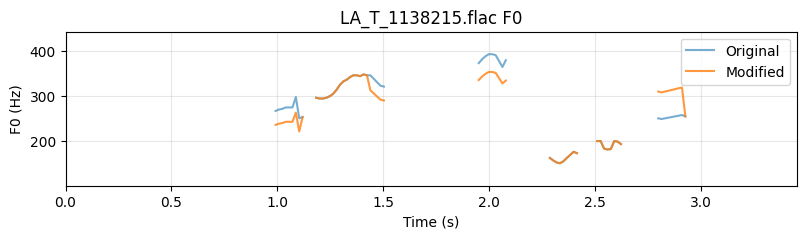

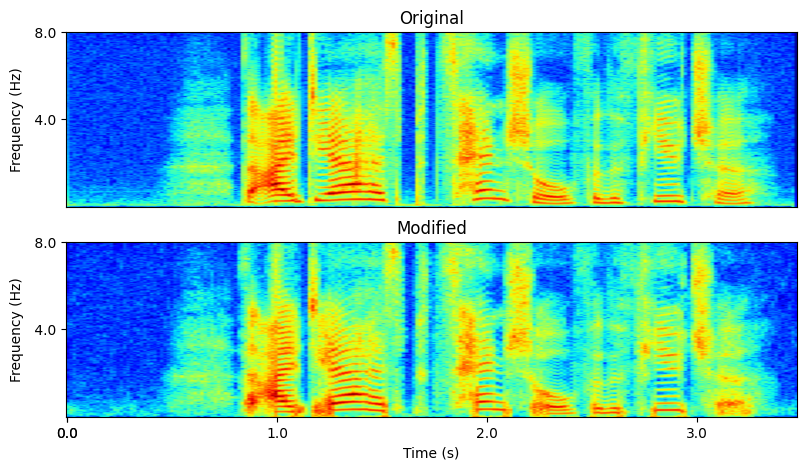

In [15]:
# plotting 
fig, axes = plt.subplots(1, 1, figsize=(9.44, 2), sharex=False)

n_frames = len(f0_traj)
time = np.arange(n_frames) * (stft_params.hop_size / stft_params.sample_rate)

valid = np.isfinite(f0_traj)
f0_min = np.nanmin(f0_traj[valid])
f0_max = np.nanmax(f0_traj[valid])
pad = 50  # Hz for visualization

axes.plot(time, f0_traj, label="Original", alpha=0.6)
axes.plot(time, f0_traj_mod, label="Modified", alpha=0.8)
axes.set_title(f"{str(filepath.name)} F0")
axes.set_ylim(f0_min - pad, f0_max + pad)
axes.set_xlim(0, max(time))
axes.legend()

axes.set_xlabel("Time (s)")
axes.set_ylabel("F0 (Hz)")
axes.grid(True, alpha=0.3)

display("Original")
display(Audio(filepath))
display("Modified")
display(Audio(data=x_mod, rate=sr))

fig = plt.figure(figsize=(9.44, 5))
axis = fig.add_subplot(2, 1, 1)
plot_spec(x, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})
axis.set_xticks([]);axis.set_xlabel(''); axis.set_title('Original')
axis = fig.add_subplot(2, 1, 2)
plot_spec(x_mod, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})
axis.set_title('Modified')

In [16]:
mod = 'shuff'

# manipulation    
f0_traj_mod = apply_f0_mod(f0_traj, mod=mod, hop_s=stft_params.hop_sec)

In [17]:
# for demonstration, show resynthesized waveform
period = stft_params.hop_size / sr * 1000
x_mod = reconstruct_wav_f0(x, f0_traj_mod, sr, period)

'Original'

'Modified'

Text(0.5, 1.0, 'Modified')

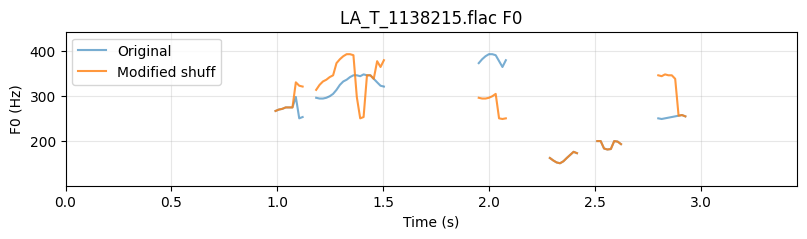

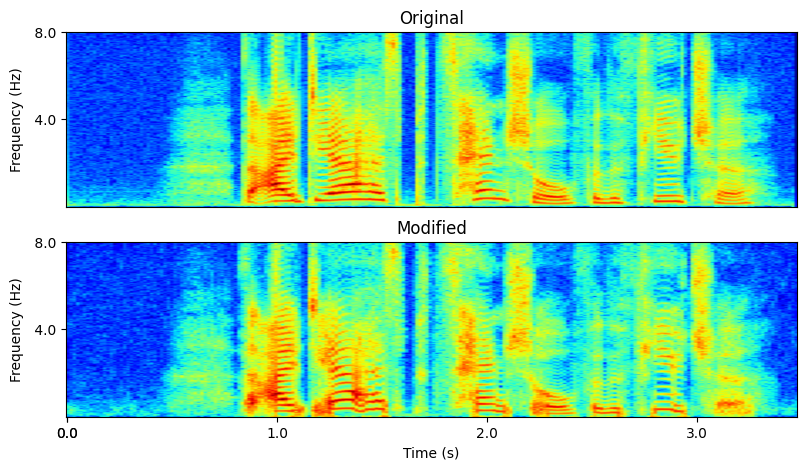

In [18]:
# plotting 
fig, axes = plt.subplots(1, 1, figsize=(9.44, 2), sharex=False)


n_frames = len(f0_traj)
time = np.arange(n_frames) * (stft_params.hop_size / stft_params.sample_rate)

valid = np.isfinite(f0_traj)
f0_min = np.nanmin(f0_traj[valid])
f0_max = np.nanmax(f0_traj[valid])
pad = 50  # Hz for visualization

axes.plot(time, f0_traj, label="Original", alpha=0.6)
axes.plot(time, f0_traj_mod, label="Modified {:s}".format(mod), alpha=0.8)
axes.set_title(f"{str(filepath.name)} F0")
axes.set_ylim(f0_min - pad, f0_max + pad)
axes.set_xlim(0, max(time))
axes.legend()

axes.set_xlabel("Time (s)")
axes.set_ylabel("F0 (Hz)")
axes.grid(True, alpha=0.3)


display("Original")
display(Audio(filepath))
display("Modified")
display(Audio(data=x_mod, rate=sr))

fig = plt.figure(figsize=(9.44, 5))
axis = fig.add_subplot(2, 1, 1)
plot_spec(x, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})
axis.set_xticks([]);axis.set_xlabel(''); axis.set_title('Original')
axis = fig.add_subplot(2, 1, 2)
plot_spec(x_mod, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})
axis.set_title('Modified')

### Case study

In [19]:
def f0_extraction(wav, stft_params=stft_params):
    """ just wrapper over extrac_f0
    """
    f0_traj = extract_f0(
        wav,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )
    return f0_traj

def f0_manipulation_shuf(f0_traj, stft_params=stft_params):
    """
    """
    f0_traj_mod = apply_f0_mod(f0_traj, mod='shuff', hop_s=stft_params.hop_sec)
    return f0_traj_mod


def f0_manipulation_shift(f0_traj, stft_params=stft_params):
    """
    """
    f0_traj_mod = apply_f0_mod(f0_traj, mod='shift', hop_s=stft_params.hop_sec)
    return f0_traj_mod

In [20]:
# actual fake data
df_concat_tts = (
    df_all[df_all[3] == 'A04']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
fake_list = df_concat_tts['path'].tolist()

# real data
df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
real_list = df_real['path'].tolist()

# smple number 
sample_num = 100
# fake data without manipulation
fake_dataframe = feat_pipeline(fake_list, f0_extraction, None, feat_name='f0', debug=sample_num)
# real data without manipulation
real_dataframe = feat_pipeline(real_list, f0_extraction, None, feat_name='f0', debug=sample_num)
# real data + manipulation (shift)
mod_shift_dataframe = feat_pipeline(real_list, f0_extraction, f0_manipulation_shift, feat_name='f0', debug=sample_num)
# real data + manipulation (shuffle)
mod_shuff_dataframe = feat_pipeline(real_list, f0_extraction, f0_manipulation_shuf, feat_name='f0', debug=sample_num)

  4%|██▋                                                                   | 100/2580 [00:38<16:05,  2.57it/s]


In [21]:
def preprocessing(data_frames):

    # ---------- support functions ----------
    def autocorr_decay(x, max_lag=50):
        x = x - np.mean(x)
        ac = np.correlate(x, x, mode='full')
        ac = ac[len(ac)//2:]
        ac /= ac[0] + 1e-8
        return np.mean(ac[1:max_lag])
    
    def f0_concat_features(f0):
        f0 = np.asarray(f0, dtype=float)
    
        # voiced only
        voiced = ~np.isnan(f0)
        f0v = f0[voiced]
        if len(f0v) < 5:
            return None
    
        logf0 = 1200 * np.log2(f0v)  # convert Hz → cents
        dlogf0 = np.diff(logf0)

        # return the two features
        return np.std(dlogf0), autocorr_decay(logf0)
        
    data_frames['dlogf0'] = data_frames.apply(lambda x: f0_concat_features(x['f0'])[0], axis=1)
    data_frames['f0_ac_decay'] = data_frames.apply(lambda x: f0_concat_features(x['f0'])[1], axis=1)
    
    return data_frames, ['dlogf0', 'f0_ac_decay']

In [22]:
# pre-processing the raw F0 feature for simply classifier
data_real, feat_names = preprocessing(real_dataframe)
data_fake, _ = preprocessing(fake_dataframe)
data_mod_shift, _ = preprocessing(mod_shift_dataframe)
data_mod_shuff, _ = preprocessing(mod_shuff_dataframe)

# add label
data_real['label'] = 1
data_fake['label'] = 0
data_mod_shift['label'] = 0
data_mod_shuff['label'] = 0

#feat_names = ['dlogf0', 'f0_ac_decay']
label_name = 'label'

In [36]:
data_real

,name,f0,dlogf0,f0_ac_decay,label
0,LA_T_1138215.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",208.68,-0.01,1
1,LA_T_1271820.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",135.14,0.06,1
2,LA_T_1272637.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",9.80,-0.10,1
3,LA_T_1276960.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",104.39,0.07,1
4,LA_T_1341447.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",122.57,-0.01,1
...,...,...,...,...,...
96,LA_T_8115679.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",154.97,0.14,1
97,LA_T_8145267.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",88.46,0.15,1
98,LA_T_8324598.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",124.08,0.11,1
99,LA_T_8449978.flac,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",92.48,-0.00,1


In [41]:
# split real data for traing and test
data_real_train, data_real_test = train_test_split(data_real, test_size=0.5, random_state=123)
data_train = pd.concat([data_real_train, data_mod_shift, data_mod_shuff], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)

model_dictionary, metrics = classifing_lazypredict(data_train, data_test, feat_names, label_name)

  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 50, number of negative: 202
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000023 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 167
[LightGBM] [Info] Number of data points in the train set: 252, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.198413 -> initscore=-1.396245
[LightGBM] [Info] Start training from score -1.396245
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best g

In [42]:
metrics

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
SGDClassifier,0.66,0.70,0.70,0.67,0.02
NearestCentroid,0.59,0.66,0.66,0.58,0.01
AdaBoostClassifier,0.68,0.60,0.60,0.66,0.13
KNeighborsClassifier,0.69,0.59,0.59,0.66,0.02
Perceptron,0.71,0.58,0.58,0.65,0.01
DecisionTreeClassifier,0.66,0.58,0.58,0.64,0.01
ExtraTreesClassifier,0.66,0.56,0.56,0.63,0.17
LGBMClassifier,0.65,0.55,0.55,0.62,0.04
RandomForestClassifier,0.64,0.55,0.55,0.62,0.23


# Spectral domain

## Oversmoothing

### Extraction

In [45]:
def get_lsf(waveform, order=10, frame_length=400, hop_length=160):
    # Ensure waveform is float64 (standard for SPTK C-wrappers)
    waveform = waveform.astype(np.float64)
    
    # 1. Framing
    # Instead of util.frame, we'll use a list comprehension for reliability
    frames = [waveform[i:i + frame_length] for i in range(0, len(waveform) - frame_length, hop_length)]
    frames = np.stack(frames)
    
    # 2. Scipy Windowing
    # 'blackman' is standard, but 'hamming' or 'hann' are also common
    window = scipy.signal.get_window('blackman', frame_length, fftbins=False)
    windowed_frames = frames * window
    

    # 3. LPC Analysis
    # Note: lpc returns (order + 1) coefficients
    lpc_coeffs = pysptk.lpc(windowed_frames, order)

    # 4. Convert LPC to LSF
    try:
        # 2. Attempt conversion
        lsf = pysptk.lpc2lsp(lpc_coeffs)
        return lsf
    except RuntimeError:
        # 3. Fallback: If it fails, the filter was likely unstable.
        # We can 'stabilize' it by slightly moving roots inside the circle
        # (Often called bandwidth expansion)
        gamma = 0.9
        lpc_stable = lpc_coeffs * (gamma ** np.arange(lpc_coeffs.shape[1]))
        return pysptk.lpc2lsp(lpc_stable)
        
    return lsf

### Manipulation

In [46]:
def apply_lsf_mod(lsf, sigma=2.0):
    # We apply the filter along axis 0 (the temporal/frame axis)
    # This blurs the transition of each individual LSF over time
    smoothed_lsf = scipy.ndimage.gaussian_filter1d(lsf, sigma=sigma, axis=0)
    
    # Ensure the LSF ordering property is maintained (stability)
    # LSFs must be strictly increasing: 0 < w1 < w2 ... < pi
    smoothed_lsf = np.sort(smoothed_lsf, axis=1)
    
    return smoothed_lsf

### Demonstration (optional)

In [47]:
p = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
f = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac'

df_all = pd.read_csv(p, sep=' ', header=None)

df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f) / f"{x}.flac"
    ))[['path']]
)

# selected_files = random.sample(df_real['path'].tolist(), 5)
selected_files = df_real['path'].tolist()

In [48]:
filepath = selected_files[0]
x, sr = load_audio(filepath)

lsf_order = 10
# extraction
lsf_traj = get_lsf(
        x,
        order= lsf_order,
        frame_length=stft_params.win_size, 
        hop_length=stft_params.hop_size     
    )

# manipulation
lsf_traj_mod = apply_lsf_mod(lsf_traj)

In [49]:
# optional to reconstruct the signal
# extraction
f0_traj = pysptk.swipe(x.astype(np.float64), fs=sr, hopsize=stft_params.hop_size, min=60, max=240, otype="pitch")                  
x_mod = synthesize_from_lsf(lsf_traj, f0_traj, stft_params.hop_size, stft_params.sample_rate)

'Original'

'Modified'

Text(0.5, 1.0, 'Modified')

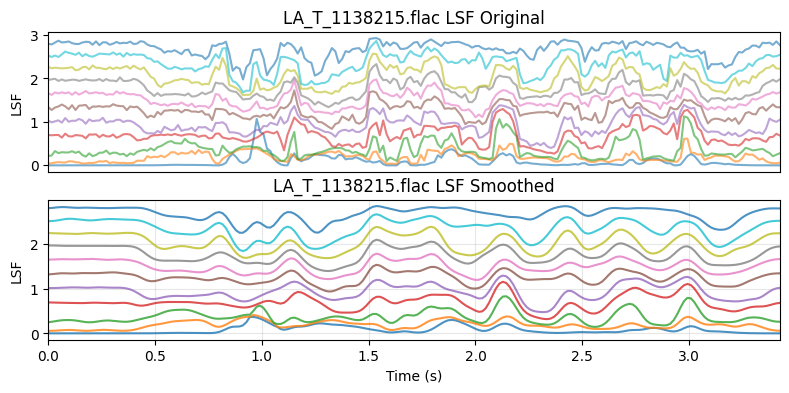

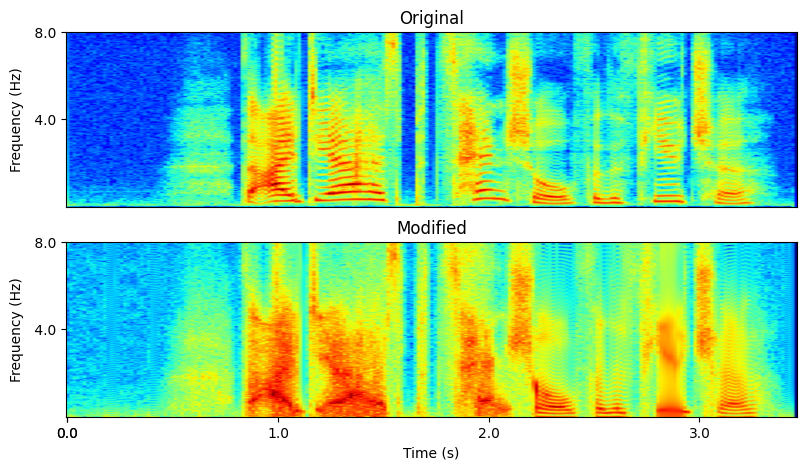

In [50]:
# plotting 
fig = plt.figure(figsize=(9.44, 4))
axis = fig.add_subplot(2, 1, 1)
n_frames = lsf_traj.shape[0]
time = np.arange(n_frames) * (stft_params.hop_size / stft_params.sample_rate)
axis.plot(time, lsf_traj, label="Original", alpha=0.6)
axis.set_title(f"{str(filepath.name)} LSF Original")
axis.set_xlim(0, max(time))
axis.set_xticks([])
axis.set_ylabel("LSF")

axis = fig.add_subplot(2, 1, 2)
axis.plot(time, lsf_traj_mod, label="Modified", alpha=0.8)
axis.set_title(f"{str(filepath.name)} LSF Smoothed")
axis.set_xlim(0, max(time))

axis.set_xlabel("Time (s)")
axis.set_ylabel("LSF")
axis.grid(True, alpha=0.3)

display("Original")
display(Audio(filepath))
display("Modified")
display(Audio(data=x_mod, rate=sr))

fig = plt.figure(figsize=(9.44, 5))
axis = fig.add_subplot(2, 1, 1)
plot_spec(x, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})
axis.set_xticks([]);axis.set_xlabel(''); axis.set_title('Original')
axis = fig.add_subplot(2, 1, 2)
plot_spec(x_mod, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})
axis.set_title('Modified')

### Case study

In [51]:
def lsf_extraction(wav, lsf_order=20, stft_params=stft_params):
    """ just wrapper over extrac_f0
    """
    lsf_traj = get_lsf(
            wav + 1e-6 * np.random.randn(len(wav)),
            order= lsf_order,
            frame_length=stft_params.win_size, 
            hop_length=stft_params.hop_size     
        )
    
    return lsf_traj

def lsf_manipulation_smoothing(lsf_traj, stft_params=stft_params):
    return apply_lsf_mod(lsf_traj)

In [52]:
# actual fake data
df_concat_tts = (
    df_all[df_all[3] == 'A03']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
fake_list = df_concat_tts['path'].tolist()

# real data
df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
real_list = df_real['path'].tolist()

# smple number 
sample_num = 100

# real data without manipulation
real_dataframe = feat_pipeline(real_list, lsf_extraction, None, feat_name='lsf', debug=sample_num)
# fake data without manipulation
fake_dataframe = feat_pipeline(fake_list, lsf_extraction, None, feat_name='lsf', debug=sample_num)
# real data + manipulation (shift)
mod_shift_dataframe = feat_pipeline(real_list, lsf_extraction, lsf_manipulation_smoothing, feat_name='lsf', debug=sample_num)
# real data + manipulation (shuffle)
mod_shuff_dataframe = feat_pipeline(real_list, lsf_extraction, lsf_manipulation_smoothing, feat_name='lsf', debug=sample_num)

  4%|██▋                                                                   | 100/2580 [00:07<03:01, 13.66it/s]


In [55]:
def preprocessing(data_frames):
    # compute the variance of each dimension
    order = data_frames.iloc[0]['lsf'].shape[1]
    feat_names = []
    for i in np.arange(order):
        feat_names.append('lsp_gv_{:d}'.format(i))
        data_frames[feat_names[i]] = data_frames['lsf'].apply(lambda x: x[:, i].std())
        
    return data_frames, feat_names
        

In [56]:
# pre-processing the raw F0 feature for simply classifier
data_real, feat_names = preprocessing(real_dataframe)
data_fake, _ = preprocessing(fake_dataframe)
data_mod_shift, _ = preprocessing(mod_shift_dataframe)
data_mod_shuff, _ = preprocessing(mod_shuff_dataframe)

# add label
data_real['label'] = 1
data_fake['label'] = 0
data_mod_shift['label'] = 0
data_mod_shuff['label'] = 0

#feat_names = ['dlogf0', 'f0_ac_decay']
label_name = 'label'

In [57]:
data_real


,name,lsf,lsp_gv_0,lsp_gv_1,lsp_gv_2,lsp_gv_3,lsp_gv_4,lsp_gv_5,lsp_gv_6,lsp_gv_7,...,lsp_gv_12,lsp_gv_13,lsp_gv_14,lsp_gv_15,lsp_gv_16,lsp_gv_17,lsp_gv_18,lsp_gv_19,lsp_gv_20,label
0,LA_T_1138215.flac,"[[0.0007657247320437158, 0.040431006575017386,...",0.12,0.06,0.08,0.09,0.12,0.12,0.13,0.12,...,0.11,0.12,0.13,0.14,0.15,0.14,0.10,0.05,0.05,1
1,LA_T_1271820.flac,"[[0.0009340045372454048, 0.05555114080612297, ...",0.11,0.05,0.09,0.09,0.11,0.08,0.09,0.11,...,0.10,0.11,0.12,0.13,0.13,0.12,0.09,0.07,0.05,1
2,LA_T_1272637.flac,"[[0.000756260798994813, 0.052452461622509515, ...",0.11,0.06,0.09,0.09,0.11,0.08,0.08,0.11,...,0.11,0.14,0.13,0.14,0.13,0.11,0.06,0.04,0.04,1
3,LA_T_1276960.flac,"[[0.0012044550380280808, 0.08341937267973362, ...",0.10,0.04,0.06,0.08,0.10,0.11,0.11,0.10,...,0.10,0.11,0.12,0.12,0.11,0.10,0.06,0.04,0.02,1
4,LA_T_1341447.flac,"[[0.00263279249497678, 0.04812924593083325, 0....",0.13,0.05,0.07,0.08,0.09,0.11,0.12,0.10,...,0.10,0.11,0.11,0.11,0.10,0.08,0.06,0.05,0.04,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,LA_T_8115679.flac,"[[0.0006913563164261851, 0.048423923729181174,...",0.20,0.05,0.07,0.07,0.09,0.11,0.13,0.11,...,0.12,0.12,0.13,0.15,0.16,0.13,0.11,0.08,0.06,1
97,LA_T_8145267.flac,"[[0.0007004241958613373, 0.05271653167819071, ...",0.07,0.05,0.08,0.08,0.10,0.11,0.12,0.11,...,0.12,0.13,0.14,0.15,0.17,0.13,0.08,0.08,0.06,1
98,LA_T_8324598.flac,"[[0.017792630474172656, 0.1084942469615752, 0....",0.09,0.05,0.07,0.11,0.11,0.08,0.11,0.11,...,0.11,0.14,0.16,0.18,0.18,0.15,0.10,0.08,0.05,1
99,LA_T_8449978.flac,"[[0.0007437122181715772, 0.044926221090761456,...",0.09,0.06,0.09,0.09,0.12,0.11,0.12,0.13,...,0.12,0.13,0.13,0.13,0.14,0.11,0.10,0.06,0.04,1


In [58]:

# split real data for traing and test
data_real_train, data_real_test = train_test_split(data_real, test_size=0.5, random_state=123)
data_train = pd.concat([data_real_train, data_mod_shift, data_mod_shuff], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)

model_dictionary, metrics = classifing_lazypredict(data_train, data_test, feat_names, label_name)

  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 50, number of negative: 202
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000091 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1800
[LightGBM] [Info] Number of data points in the train set: 252, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.198413 -> initscore=-1.396245
[LightGBM] [Info] Start training from score -1.396245
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

In [59]:
metrics


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
XGBClassifier,0.73,0.79,0.79,0.74,0.04
AdaBoostClassifier,0.72,0.78,0.78,0.72,0.16
LGBMClassifier,0.70,0.76,0.76,0.71,0.07
BaggingClassifier,0.70,0.73,0.73,0.71,0.05
CalibratedClassifierCV,0.62,0.69,0.69,0.62,0.04
RandomForestClassifier,0.49,0.60,0.60,0.46,0.23
RidgeClassifierCV,0.47,0.57,0.57,0.44,0.02
LabelPropagation,0.45,0.57,0.57,0.41,0.04
LabelSpreading,0.45,0.57,0.57,0.41,0.02
